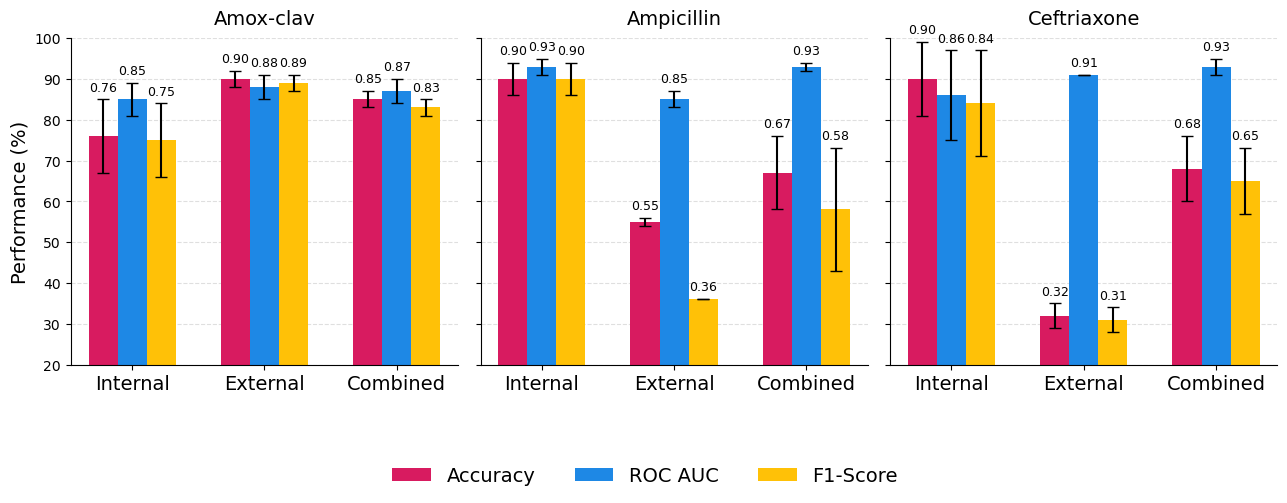

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data
mean_acc_df = pd.read_csv(
    "diagram_data/filtered_results_acc.csv",
    index_col=0,
)
mean_acc_df_std = pd.read_csv(
    "diagram_data/filtered_results_acc_std.csv",
    index_col=0,
)

mean_roc_df = pd.read_csv(
    "diagram_data/filtered_results_roc.csv",
    index_col=0,
)
mean_roc_df_std = pd.read_csv(
    "diagram_data/filtered_results_roc_std.csv",
    index_col=0,
)

mean_f1_df = pd.read_csv(
    "diagram_data/filtered_results_f1.csv",
    index_col=0,
)
mean_f1_df_std = pd.read_csv(
    "diagram_data/filtered_results_f1_std.csv",
    index_col=0,
)


# Plot settings
width = 0.22

colors = {
    "Accuracy": "#D81B60",
    "ROC AUC": "#1E88E5",
    "F1-Score": "#FFC107",
}

antibiotics = mean_acc_df.index

fig, axes = plt.subplots(
    1,
    len(antibiotics),
    figsize=(13, 4.5),
    sharey=True,
)

if len(antibiotics) == 1:
    axes = [axes]


for ax, antibiotic in zip(axes, antibiotics):

    acc = mean_acc_df.loc[antibiotic]
    acc_std = mean_acc_df_std.loc[antibiotic]

    roc = mean_roc_df.loc[antibiotic]
    roc_std = mean_roc_df_std.loc[antibiotic]

    f1 = mean_f1_df.loc[antibiotic]
    f1_std = mean_f1_df_std.loc[antibiotic]

    setups = ["internal", "external", "combined"]
    setup_labels = ["Internal", "External", "Combined"]

    x_positions = np.arange(len(setups))

    bars_acc = ax.bar(
        x_positions - width,
        acc[setups],
        width,
        yerr=acc_std[setups],
        capsize=4,
        label="Accuracy",
        color=colors["Accuracy"],
    )

    bars_roc = ax.bar(
        x_positions,
        roc[setups],
        width,
        yerr=roc_std[setups],
        capsize=4,
        label="ROC AUC",
        color=colors["ROC AUC"],
    )

    bars_f1 = ax.bar(
        x_positions + width,
        f1[setups],
        width,
        yerr=f1_std[setups],
        capsize=4,
        label="F1-Score",
        color=colors["F1-Score"],
    )

    for bars in [bars_acc, bars_roc, bars_f1]:
        ax.bar_label(
            bars,
            labels=[f"{value:.2f}" for value in bars.datavalues],
            padding=4,
            fontsize=9,
        )

    ax.set_title(
        antibiotic,
        fontsize=14,
        pad=10,
    )

    ax.set_xticks(x_positions)
    ax.set_xticklabels(
        setup_labels,
        fontsize=14,
    )

    ax.set_ylim(0.20, 1.00)

    ax.set_yticks(np.arange(0.2, 1.01, 0.1))
    ax.set_yticklabels([f"{int(value * 100)}" for value in np.arange(0.2, 1.01, 0.1)])

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.4,
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


axes[0].set_ylabel(
    "Performance (%)",
    fontsize=14,
)


handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.01),
    ncol=3,
    frameon=False,
    fontsize=14,
)


plt.tight_layout(rect=[0, 0.08, 1, 1])


plt.savefig(
    "diagram_data/performance_comparison_by_antibiotic.pdf",
    dpi=1000,
    bbox_inches="tight",
)

plt.savefig(
    "diagram_data/performance_comparison_by_antibiotic.jpg",
    dpi=1000,
    bbox_inches="tight",
)

plt.show()

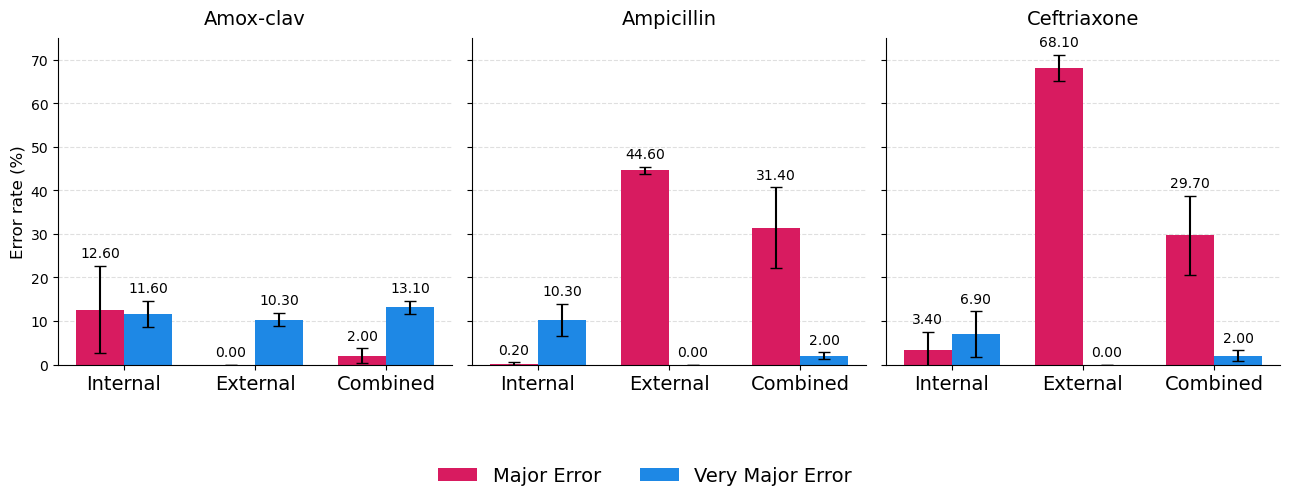

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load data
mean_vme_df = pd.read_csv(
    "diagram_data/filtered_results_vme.csv",
    index_col=0,
)

mean_vme_df_std = pd.read_csv(
    "diagram_data/filtered_results_vme_std.csv",
    index_col=0,
)

mean_me_df = pd.read_csv(
    "diagram_data/filtered_results_me.csv",
    index_col=0,
)

mean_me_df_std = pd.read_csv(
    "diagram_data/filtered_results_me_std.csv",
    index_col=0,
)


# Plot settings
width = 0.22

colors = {
    "Major Error": "#D81B60",
    "Very Major Error": "#1E88E5",
}

antibiotics = mean_me_df.index

fig, axes = plt.subplots(
    1,
    len(antibiotics),
    figsize=(13, 4.5),
    sharey=True,
)

if len(antibiotics) == 1:
    axes = [axes]


for ax, antibiotic in zip(axes, antibiotics):

    me = mean_me_df.loc[antibiotic]
    me_std = mean_me_df_std.loc[antibiotic]

    vme = mean_vme_df.loc[antibiotic]
    vme_std = mean_vme_df_std.loc[antibiotic]

    x = np.arange(len(me.index)) * 0.6

    bars_me = ax.bar(
        x - width / 2,
        me,
        width,
        yerr=me_std,
        capsize=4,
        label="Major Error",
        color=colors["Major Error"],
    )

    bars_vme = ax.bar(
        x + width / 2,
        vme,
        width,
        yerr=vme_std,
        capsize=4,
        label="Very Major Error",
        color=colors["Very Major Error"],
    )

    # Add decimal values above bars
    for bars in [bars_me, bars_vme]:
        ax.bar_label(
            bars,
            labels=[f"{value:.2f}" for value in bars.datavalues],
            padding=4,
            fontsize=10,
        )

    ax.set_title(
        antibiotic,
        fontsize=14,
        pad=10,
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        ["Internal", "External", "Combined"],
        fontsize=14,
    )

    ax.set_ylim(0.0, 75.0)
    ax.set_yticks(np.arange(0, 76, 10))

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.4,
    )
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


axes[0].set_ylabel(
    "Error rate (%)",
    fontsize=12,
)


handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.01),
    ncol=2,
    frameon=False,
    fontsize=14,
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    "diagram_data/error_rates_by_antibiotic.pdf",
    dpi=1000,
    bbox_inches="tight",
)

plt.savefig(
    "diagram_data/error_rates_by_antibiotic.jpg",
    dpi=1000,
    bbox_inches="tight",
)

plt.show()